In [4]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os
import PIL
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [4]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 184s 1us/step


In [9]:
data_dir = tf.keras.utils.get_file('flower_photos',origin='.', cache_dir='.', untar=True)

In [10]:
data_dir

'.\\datasets\\flower_photos'

In [11]:
import pathlib
data_dir = pathlib.Path(data_dir)
data_dir

WindowsPath('datasets/flower_photos')

In [12]:
list(data_dir.glob('*/*.jpg'))

[WindowsPath('datasets/flower_photos/daisy/100080576_f52e8ee070_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10140303196_b88d3d6cec.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172379554_b296050f82_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172567486_2748826a8b.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10172636503_21bededa75_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/102841525_bd6628ae3c.jpg'),
 WindowsPath('datasets/flower_photos/daisy/1031799732_e7f4008c03.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10391248763_1d16681106_n.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10437754174_22ec990b77_m.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10437770546_8bb6f7bdd3_m.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10437929963_bc13eebe0c.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10466290366_cc72e33532.jpg'),
 WindowsPath('datasets/flower_photos/daisy/10466558316_a7198b87e2.jpg'),
 WindowsPath('datasets/flower_photos/daisy/1

In [13]:
image_count = len(list(data_dir.glob('*/*.jpg')))
image_count

3670

In [35]:
# Store all respective flower paths in the respective name section
flowers_images_dict = {
    'roses' : list(data_dir.glob('roses/*')),
    'daisy' : list(data_dir.glob('daisy/*')),
    'dandelion' : list(data_dir.glob('dandelion/*')),
    'sunflowers' : list(data_dir.glob('sunflowers/*')),
    'tulips' : list(data_dir.glob('tulips/*')),
}

In [36]:
flowers_labels_dict = {
    'roses': 0,
    'daisy': 1, 
    'dandelion': 2, 
    'sunflowers': 3,
    'tulips': 4,
}

In [37]:
def show_flower(name, num: int):
    return PIL.Image.open(str(name[num]))

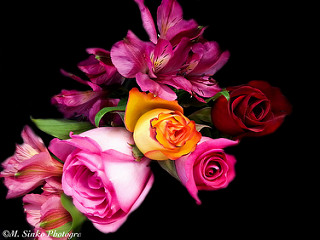

In [17]:
show_flower(flowers_images_dict['roses'], 6)

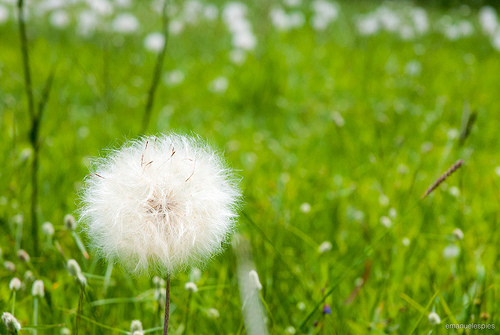

In [18]:
show_flower(flowers_images_dict['dandelion'], 11)

### Reading images with cv2

In [19]:
# openCV read the image and convert it in 3D numpy array

In [20]:
img = cv2.imread(str(flowers_images_dict['roses'][0]))
img

array([[[ 0, 15,  6],
        [ 0, 15,  6],
        [ 0, 17,  8],
        ...,
        [24, 51, 31],
        [25, 52, 32],
        [26, 53, 33]],

       [[ 7, 22, 14],
        [ 7, 22, 14],
        [ 6, 21, 13],
        ...,
        [20, 46, 30],
        [23, 49, 33],
        [25, 51, 35]],

       [[12, 23, 15],
        [12, 23, 15],
        [11, 22, 14],
        ...,
        [20, 42, 30],
        [23, 45, 33],
        [26, 48, 36]],

       ...,

       [[19, 30, 27],
        [14, 24, 18],
        [12, 20, 13],
        ...,
        [ 4, 13,  3],
        [ 0,  8,  1],
        [ 0,  5,  0]],

       [[19, 30, 28],
        [18, 27, 24],
        [15, 23, 16],
        ...,
        [ 3, 12,  2],
        [ 1,  9,  2],
        [ 0,  7,  2]],

       [[ 9, 19, 19],
        [17, 25, 24],
        [22, 29, 24],
        ...,
        [ 1, 12,  2],
        [ 2, 10,  3],
        [ 3, 11,  4]]], shape=(240, 179, 3), dtype=uint8)

In [32]:
img.shape # X, Y , RGB channel

(335, 500, 3)

In [33]:
# resize image
cv2.resize(img, (180, 180)).shape 

(180, 180, 3)

In [38]:
X, y = [], []

for flower_name , images in flowers_images_dict.items():
    for image in images:
        img = cv2.imread(str(image))
        resized_img = cv2.resize(img,(180,180))
        X.append(resized_img)
        y.append([flowers_labels_dict[flower_name]])

In [39]:
y[:5]

[[0], [0], [0], [0], [0]]

In [40]:
X = np.array(X)
y = np.array(y)

### Train Test split

In [41]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2,random_state=0)

In [42]:
len(X_train)

2936

In [43]:
len(X_test)

734

In [44]:
# Scaling
X_train_scaled = X_train / 265
X_test_scaled = X_test / 265

In [45]:
X_train_scaled[0]

array([[[0.0490566 , 0.10943396, 0.16981132],
        [0.0490566 , 0.11320755, 0.16603774],
        [0.04528302, 0.10188679, 0.16226415],
        ...,
        [0.01509434, 0.01509434, 0.06792453],
        [0.01509434, 0.01886792, 0.06792453],
        [0.01132075, 0.01886792, 0.06037736]],

       [[0.0490566 , 0.10943396, 0.16603774],
        [0.04528302, 0.10566038, 0.16603774],
        [0.04528302, 0.10188679, 0.16226415],
        ...,
        [0.        , 0.01132075, 0.06415094],
        [0.00377358, 0.01509434, 0.06415094],
        [0.00377358, 0.01132075, 0.05660377]],

       [[0.05283019, 0.11320755, 0.17358491],
        [0.05283019, 0.10943396, 0.16981132],
        [0.0490566 , 0.10943396, 0.16981132],
        ...,
        [0.        , 0.01132075, 0.06415094],
        [0.        , 0.00754717, 0.06037736],
        [0.00377358, 0.01509434, 0.05283019]],

       ...,

       [[0.06415094, 0.13962264, 0.18113208],
        [0.06792453, 0.13962264, 0.18867925],
        [0.07169811, 0

### Model building

In [30]:
# CNN

num_classes = 5  # because we hv 5 diff flower name 

model = Sequential([
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    # Dense network
    layers.Flatten(), # convert 2D to 1D
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.fit(X_train_scaled, y_train, epochs=20)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 195ms/step - accuracy: 0.3495 - loss: 1.4603
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 197ms/step - accuracy: 0.5804 - loss: 1.0407
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 199ms/step - accuracy: 0.6642 - loss: 0.8635
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 226ms/step - accuracy: 0.7667 - loss: 0.6378
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 218ms/step - accuracy: 0.8369 - loss: 0.4528
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 196ms/step - accuracy: 0.9053 - loss: 0.2775
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 195ms/step - accuracy: 0.9561 - loss: 0.1422
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 192ms/step - accuracy: 0.9601 - loss: 0.1261
Epoch 9/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 197ms/step - accuracy: 0.9762 - loss: 0.0873
Epoch 10/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 190ms/step - accuracy: 0.9877 - loss: 0.0538
Epoch 11/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 192ms/step - accuracy: 0.9911 - loss: 0.0321
Epoch 12/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 19

In [32]:
model.evaluate(X_test_scaled, y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.6485 - loss: 2.5981


[2.5980935096740723, 0.6485013365745544]

### Predictions

In [33]:
predictions = model.predict(X_test_scaled)
predictions

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step


array([[ -8.580507  ,  34.97515   ,  -0.93163234, -24.712345  ,
        -14.384286  ],
       [ 12.787891  ,  -0.2995853 , -13.557418  ,  -7.9411607 ,
          4.4521866 ],
       [ -2.8095758 ,  -1.1829563 ,  14.0971775 , -12.124815  ,
         -6.4997907 ],
       ...,
       [ -2.656039  ,   4.345692  ,   8.711493  , -12.256365  ,
         -5.0897346 ],
       [  0.33803773,  -1.5600533 ,  -0.75170815,   4.787668  ,
          2.738516  ],
       [ -1.5266864 ,   0.6091756 ,   8.34556   ,  -7.751511  ,
         -1.9985025 ]], shape=(734, 5), dtype=float32)

In [34]:
# converting above output in probability score
score = tf.nn.softmax(predictions[0])
score

<tf.Tensor: shape=(5,), dtype=float32, numpy=
array([1.2134413e-19, 1.0000000e+00, 2.5461374e-16, 1.1968779e-26,
       3.6599009e-22], dtype=float32)>

In [35]:
np.argmax(score) # get max values

np.int64(1)

In [36]:
# above prediction 1 [ 1 -> indicated it is daisy ]
# now checking y_test 

y_test[0]

array([1])

In [37]:
# since both same, means model predicted correct

#### In above the model give accuracy of 99% but for test case it give only 64% , it means Overfitting 

Now, Identifying Overfitting


#### With the help of data_augmentation we can produce more sample from the same sample which makes model more understanding , for eg. A simple picture of rose can be rotated , zoom , contrast , sharpness etc. which form more sample for training

By doing this , the model become more robust so that it won't be overfit and it generalize well

In [47]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", input_shape=(180, 180, 3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1), 
])

C:\Users\rosha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [48]:
# we can do : RandomZoom , RandomRotate, RandomContrast, RandomFlip etc.

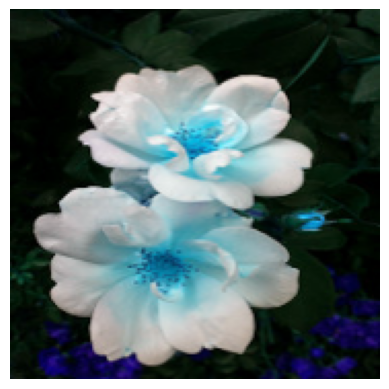

In [49]:
plt.axis('off')
plt.imshow(X[0])

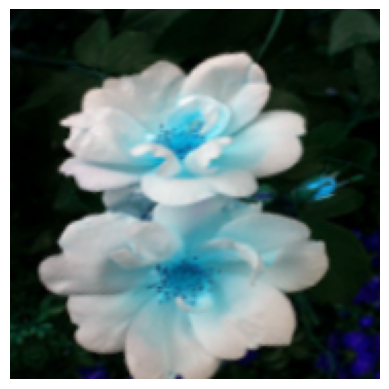

In [50]:
plt.axis('off')
plt.imshow(data_augmentation(X)[0].numpy().astype("uint8"))

In [51]:
# CNN with data_augmentation

num_classes = 5  # because we hv 5 diff flower name 

model = Sequential([
    data_augmentation,
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),

    # Dense network
    layers.Flatten(), # convert 2D to 1D
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])

model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.fit(X_train_scaled, y_train, epochs=20)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 28s 243ms/step - accuracy: 0.4206 - loss: 1.3096
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 259ms/step - accuracy: 0.5589 - loss: 1.0755
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 236ms/step - accuracy: 0.6311 - loss: 0.9665
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 241ms/step - accuracy: 0.6448 - loss: 0.8884
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 234ms/step - accuracy: 0.6747 - loss: 0.8401
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 236ms/step - accuracy: 0.6975 - loss: 0.7784
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 236ms/step - accuracy: 0.7309 - loss: 0.7319
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 232ms/step - accuracy: 0.7391 - loss: 0.6866
Epoch 9/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 234ms/step - accuracy: 0.7316 - loss: 0.6721
Epoch 10/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 234ms/step - accuracy: 0.7609 - loss: 0.6217
Epoch 11/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 233ms/step - accuracy: 0.7602 - loss: 0.6261
Epoch 12/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22

In [53]:
model.evaluate(X_test_scaled, y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7466 - loss: 0.7469


[0.7468554973602295, 0.7465940117835999]

#### Now, by doing data augementation the test accuracy increase from 64% to 74%.